# UNSW-NB15 IDS: Complete Binary IDS Pipeline (No MLP, No Model Saving)

This notebook is the cleaned end-to-end version of the previous binary IDS pipeline. It keeps the established preprocessing, exact 19-feature selection, leakage checks, hyperparameter tuning, fresh 5-fold CV, out-of-fold predictions, threshold optimization, model comparison, and complementary-error analysis.

### Models
- Random Forest
- XGBoost
- LightGBM
- CatBoost
- LinearSVC (SVM)

### Deliberately removed
- MLP, because it was comparatively less competitive for this project and added substantial training/runtime cost.
- Repeated official-test evaluation, because the official test results have already been obtained and are being treated as frozen results.
- Model saving, as requested.

### Pipeline
1. Load the official UNSW-NB15 training set
2. Clean and one-hot encode categorical variables
3. Use the exact 19 selected features
4. Run leakage/sanity checks
5. Tune five models with 3-fold RandomizedSearchCV
6. Re-evaluate tuned models with fresh 5-fold Stratified CV
7. Generate out-of-fold scores
8. Optimize thresholds using OOF predictions
9. Compare model performance and fold stability
10. Analyze complementary errors to justify the ensemble stage

> **Important:** The official test set is not used in this notebook. Its previously obtained results remain the final frozen external benchmark. No model is saved to disk.

In [1]:
# 1. Imports and configuration

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    precision_recall_curve, roc_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
TRAIN_PATH = "UNSW_NB15_training-set.csv"
TARGET = "label"

SELECTED_FEATURES = [
    "ct_dst_src_ltm", "sttl", "sbytes", "smean", "dmean", "dttl",
    "dbytes", "ct_state_ttl", "service_none", "ct_dst_sport_ltm",
    "dload", "proto_udp", "sloss", "state_int", "proto_tcp",
    "service_http", "tcprtt", "swin", "response_body_len"
]

N_TUNING_FOLDS = 3
N_EVAL_FOLDS = 5

print("Configuration loaded.")
print("Selected feature count:", len(SELECTED_FEATURES))

Configuration loaded.
Selected feature count: 19


In [2]:
# 2. Locate and load the official training file

print("Current working directory:", os.getcwd())

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(
        f"Could not find {TRAIN_PATH}. Put the CSV in the notebook working directory "
        "or change TRAIN_PATH above."
    )

train_df = pd.read_csv(TRAIN_PATH)

print("Train shape:", train_df.shape)
display(train_df.head())

Current working directory: C:\Users\aksha\OneDrive\Pictures\Documents\Dummy
Train shape: (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [3]:
# 3. Basic dataset checks

print("Number of columns:", len(train_df.columns))
print("Columns:")
print(train_df.columns.tolist())

print("\nMissing values by column:")
display(train_df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))

print("\nTarget distribution:")
display(train_df[TARGET].value_counts().to_frame("count"))
display(train_df[TARGET].value_counts(normalize=True).rename("proportion").to_frame())

Number of columns: 45
Columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Missing values by column:


,missing
id,0
dwin,0
synack,0
ackdat,0
smean,0
dmean,0
trans_depth,0
response_body_len,0
ct_srv_src,0
ct_state_ttl,0



Target distribution:


,count
label,
1,119341
0,56000


,proportion
label,
1,0.680622
0,0.319378


In [4]:
# 4. Clean and one-hot encode

def prepare_dataframe(df):
    out = df.copy()

    # Remove identifier and multiclass target information.
    out = out.drop(columns=["id", "attack_cat"], errors="ignore")

    cat_cols = [c for c in ["proto", "service", "state"] if c in out.columns]

    for col in cat_cols:
        out[col] = (
            out[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace("-", "none")
        )

    X = pd.get_dummies(
        out.drop(columns=[TARGET]),
        columns=cat_cols,
        drop_first=False
    )

    y = out[TARGET].astype(int)
    return X, y

X_train_all, y_train = prepare_dataframe(train_df)

print("Encoded train shape:", X_train_all.shape)

Encoded train shape: (175341, 194)


In [5]:
# 5. Apply the exact 19 selected features

missing_selected = [c for c in SELECTED_FEATURES if c not in X_train_all.columns]

if missing_selected:
    raise ValueError(f"Selected features missing after encoding: {missing_selected}")

X_selected = X_train_all[SELECTED_FEATURES].copy()

print("Final selected feature count:", X_selected.shape[1])
print(SELECTED_FEATURES)

Final selected feature count: 19
['ct_dst_src_ltm', 'sttl', 'sbytes', 'smean', 'dmean', 'dttl', 'dbytes', 'ct_state_ttl', 'service_none', 'ct_dst_sport_ltm', 'dload', 'proto_udp', 'sloss', 'state_int', 'proto_tcp', 'service_http', 'tcprtt', 'swin', 'response_body_len']


In [6]:
# 6. Leakage and sanity checks

assert TARGET not in X_selected.columns
assert "attack_cat" not in X_selected.columns
assert "id" not in X_selected.columns

print("Target leakage check: passed")
print("Identifier removal check: passed")
print("Selected-feature existence check: passed")

print("\nDuplicate rows in selected training features:", X_selected.duplicated().sum())
print("Duplicate full training rows:", train_df.duplicated().sum())

print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("count"))
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

Target leakage check: passed
Identifier removal check: passed
Selected-feature existence check: passed

Duplicate rows in selected training features: 89709
Duplicate full training rows: 0

Training class distribution:


,count
label,
1,119341
0,56000


,proportion
label,
1,0.680622
0,0.319378


## 7. Hyperparameter tuning strategy

Hyperparameter tuning is performed only on the training data using **3-fold Stratified RandomizedSearchCV**. The optimization metric is F1. The tuned configurations are then evaluated again with a separate 5-fold Stratified CV stage.

In [7]:
# 8. Model definitions and tuning spaces

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

models_and_spaces = {

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "n_estimators": [150, 250, 350],
            "max_depth": [None, 15, 20, 30],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2", 0.7]
        },
        10
    ),

    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "n_estimators": [150, 250, 350, 500],
            "max_depth": [3, 5, 7, 9],
            "learning_rate": [0.03, 0.05, 0.1, 0.2],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0],
            "min_child_weight": [1, 3, 5],
            "gamma": [0, 0.1, 0.3],
            "scale_pos_weight": [scale_pos_weight]
        },
        15
    ),

    "LightGBM": (
        LGBMClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),
        {
            "n_estimators": [150, 250, 350, 500],
            "learning_rate": [0.03, 0.05, 0.1],
            "num_leaves": [15, 31, 63],
            "max_depth": [-1, 10, 20],
            "min_child_samples": [10, 20, 40],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0]
        },
        12
    ),

    "CatBoost": (
        CatBoostClassifier(
            auto_class_weights="Balanced",
            random_seed=RANDOM_STATE,
            verbose=False,
            thread_count=-1
        ),
        {
            "iterations": [200, 300, 500],
            "depth": [5, 6, 7, 8],
            "learning_rate": [0.03, 0.05, 0.1],
            "l2_leaf_reg": [1, 3, 5, 7],
            "border_count": [64, 128, 254]
        },
        10
    ),

    # LinearSVC is used instead of RBF SVC because the previous RBF
    # implementation was impractical inside repeated CV on UNSW-NB15.
    "SVM": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearSVC(
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE
            ))
        ]),
        {
            "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
        },
        6
    )
}

print("Models:", list(models_and_spaces.keys()))

Models: ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'SVM']


In [8]:
# 9. Hyperparameter tuning

tuning_cv = StratifiedKFold(
    n_splits=N_TUNING_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

tuned_models = {}
tuning_rows = []

for name, (estimator, param_space, n_iter) in models_and_spaces.items():

    print("\n" + "=" * 80)
    print("TUNING:", name)
    print("=" * 80)

    start = time.time()

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_space,
        n_iter=n_iter,
        scoring="f1",
        cv=tuning_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_selected, y_train)

    elapsed = time.time() - start
    tuned_models[name] = search.best_estimator_

    tuning_rows.append({
        "Model": name,
        "Best_CV_F1": search.best_score_,
        "Tuning_Time_min": elapsed / 60,
        "Best_Params": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 6))
    print("Time:", round(elapsed / 60, 2), "minutes")
    print("Best parameters:")
    print(search.best_params_)

tuning_summary = pd.DataFrame(tuning_rows)
display(tuning_summary)


TUNING: Random Forest
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV F1: 0.967507
Time: 1.73 minutes
Best parameters:
{'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}

TUNING: XGBoost
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV F1: 0.9637
Time: 0.56 minutes
Best parameters:
{'subsample': 0.8, 'scale_pos_weight': 0.469243596081816, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 7, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}

TUNING: LightGBM
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV F1: 0.964655
Time: 0.6 minutes
Best parameters:
{'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 10, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

TUNING: CatBoost
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV F1: 0.963058
Time: 1.81 minutes
Best parameters:
{'learning_rate'

,Model,Best_CV_F1,Tuning_Time_min,Best_Params
0,Random Forest,0.967507,1.734089,"{'n_estimators': 150, 'min_samples_split': 2, ..."
1,XGBoost,0.963700,0.563469,"{'subsample': 0.8, 'scale_pos_weight': 0.46924..."
2,LightGBM,0.964655,0.598978,"{'subsample': 0.8, 'num_leaves': 63, 'n_estima..."
3,CatBoost,0.963058,1.807963,"{'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iter..."
4,SVM,0.946744,0.198801,{'model__C': 1}


## 10. Fresh 5-fold evaluation of the tuned models

The tuning stage selected hyperparameters. This separate 5-fold Stratified CV measures the tuned configurations and stores **out-of-fold (OOF) scores**. These OOF scores are used for threshold optimization and complementary-error analysis.

In [9]:
# 11. Metric helpers

def get_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def metrics_from_scores(y_true, scores, threshold=0.5):
    y_pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "FPR": fp / (fp + tn) if (fp + tn) > 0 else 0.0,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "TP": tp
    }

In [10]:
# 12. Fresh 5-fold CV + out-of-fold predictions

evaluation_cv = StratifiedKFold(
    n_splits=N_EVAL_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = {}
oof_scores = {}
fold_rows = []

for name, tuned_model in tuned_models.items():

    print("\n" + "=" * 80)
    print("5-FOLD EVALUATION:", name)
    print("=" * 80)

    start_total = time.time()
    scores_oof = np.zeros(len(y_train))

    for fold, (train_idx, val_idx) in enumerate(
        evaluation_cv.split(X_selected, y_train), 1
    ):

        fold_start = time.time()

        X_tr = X_selected.iloc[train_idx]
        X_va = X_selected.iloc[val_idx]
        y_tr = y_train.iloc[train_idx]
        y_va = y_train.iloc[val_idx]

        model = clone(tuned_model)
        model.fit(X_tr, y_tr)

        score = get_score(model, X_va)
        scores_oof[val_idx] = score

        fold_metrics = metrics_from_scores(y_va, score, threshold=0.5)
        fold_metrics["Model"] = name
        fold_metrics["Fold"] = fold
        fold_metrics["Time_sec"] = time.time() - fold_start
        fold_rows.append(fold_metrics)

        print(
            f"{name} | Fold {fold}/5 | "
            f"{fold_metrics['Time_sec']:.1f}s | "
            f"F1={fold_metrics['F1']:.4f} | "
            f"AUC={fold_metrics['ROC-AUC']:.4f}"
        )

    oof_scores[name] = scores_oof
    cv_results[name] = pd.DataFrame(
        [r for r in fold_rows if r["Model"] == name]
    )

    print(
        f"Completed {name}: "
        f"{(time.time() - start_total) / 60:.2f} min"
    )


5-FOLD EVALUATION: Random Forest
Random Forest | Fold 1/5 | 2.1s | F1=0.9667 | AUC=0.9931
Random Forest | Fold 2/5 | 2.1s | F1=0.9682 | AUC=0.9932
Random Forest | Fold 3/5 | 2.1s | F1=0.9696 | AUC=0.9938
Random Forest | Fold 4/5 | 2.1s | F1=0.9700 | AUC=0.9941
Random Forest | Fold 5/5 | 2.1s | F1=0.9673 | AUC=0.9933
Completed Random Forest: 0.17 min

5-FOLD EVALUATION: XGBoost
XGBoost | Fold 1/5 | 2.2s | F1=0.9630 | AUC=0.9932
XGBoost | Fold 2/5 | 2.1s | F1=0.9635 | AUC=0.9932
XGBoost | Fold 3/5 | 2.1s | F1=0.9651 | AUC=0.9937
XGBoost | Fold 4/5 | 2.1s | F1=0.9659 | AUC=0.9940
XGBoost | Fold 5/5 | 2.0s | F1=0.9633 | AUC=0.9929
Completed XGBoost: 0.17 min

5-FOLD EVALUATION: LightGBM
LightGBM | Fold 1/5 | 2.2s | F1=0.9634 | AUC=0.9934
LightGBM | Fold 2/5 | 2.2s | F1=0.9639 | AUC=0.9936
LightGBM | Fold 3/5 | 2.2s | F1=0.9662 | AUC=0.9941
LightGBM | Fold 4/5 | 1.6s | F1=0.9673 | AUC=0.9943
LightGBM | Fold 5/5 | 1.6s | F1=0.9634 | AUC=0.9933
Completed LightGBM: 0.16 min

5-FOLD EVALUATION

In [11]:
# 13. 5-fold CV summary at default 0.50 threshold

cv_fold_table = pd.DataFrame(fold_rows)

cv_summary = (
    cv_fold_table
    .groupby("Model")
    [["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "FPR",
      "FP", "FN", "TN", "TP", "Time_sec"]]
    .agg(["mean", "std"])
)

display(cv_summary.round(4))

Accuracy         Precision          Recall              F1  \
                  mean     std      mean     std    mean     std    mean   
Model                                                                      
CatBoost        0.9516  0.0021    0.9780  0.0011  0.9502  0.0023  0.9639   
LightGBM        0.9528  0.0024    0.9781  0.0012  0.9519  0.0025  0.9648   
Random Forest   0.9570  0.0019    0.9710  0.0011  0.9657  0.0019  0.9684   
SVM             0.8154  0.0020    0.9923  0.0003  0.7345  0.0031  0.8441   
XGBoost         0.9519  0.0017    0.9774  0.0011  0.9513  0.0016  0.9642   

                      ROC-AUC          ...     FP               FN           \
                  std    mean     std  ...   mean      std    mean      std   
Model                                  ...                                    
CatBoost       0.0016  0.9933  0.0004  ...  510.8  24.2631  1188.0  54.4334   
LightGBM       0.0018  0.9937  0.0005  ...  508.2  27.9768  1148.0  59.4433   
Random Forest  0.0014  0.9935  0.0004  ...  688.2  26.1763   818.0  46.1519   
SVM            0.0020  0.9768  0.0007  ...  136.6   6.0249  6338.0  74.8432   
XGBoost        0.0013  0.9934  0.0004  ...  525.6  25.1257  1162.8  38.1798   

                    TN                TP          Time_sec          
                  mean      std     mean      std     mean     std  
Model                                                               
CatBoost       10689.2  24.2631  22680.2  54.1590   6.7453  0.1206  
LightGBM       10691.8  27.9768  22720.2  59.2385   1.9583  0.3346  
Random Forest  10511.8  26.1763  23050.2  45.8716   2.0783  0.0343  
SVM            11063.4   6.0249  17530.2  74.9880   1.6557  0.5176  
XGBoost        10674.4  25.1257  22705.4  37.9183   2.0790  0.0495  

[5 rows x 22 columns]

## 14. Threshold optimization

The default 0.50 threshold is not automatically the correct operating point for an IDS. The primary objective remains **maximize recall subject to FPR < 2%** on the OOF predictions. If no threshold satisfies the constraint, the lowest-FPR operating point is selected.

In [12]:
# 15. Threshold sweep

threshold_grid = np.round(np.linspace(0.05, 0.95, 181), 3)
threshold_results = {}
threshold_summary_rows = []

for name, scores in oof_scores.items():

    rows = []

    for threshold in threshold_grid:
        m = metrics_from_scores(y_train, scores, threshold=threshold)
        m["Threshold"] = threshold
        rows.append(m)

    result = pd.DataFrame(rows)
    eligible = result[result["FPR"] < 0.02].copy()

    if len(eligible) > 0:
        best = eligible.sort_values(
            ["Recall", "F1", "Precision"],
            ascending=False
        ).iloc[0]
        rule = "Max recall with FPR < 2%"
    else:
        best = result.sort_values(
            ["FPR", "Recall"],
            ascending=[True, False]
        ).iloc[0]
        rule = "Lowest FPR because no threshold met FPR < 2%"

    threshold_results[name] = result

    threshold_summary_rows.append({
        "Model": name,
        "Threshold": best["Threshold"],
        "Accuracy": best["Accuracy"],
        "Precision": best["Precision"],
        "Recall": best["Recall"],
        "F1": best["F1"],
        "ROC-AUC": best["ROC-AUC"],
        "FPR": best["FPR"],
        "FP": best["FP"],
        "FN": best["FN"],
        "TN": best["TN"],
        "TP": best["TP"],
        "Selection_Rule": rule
    })

threshold_summary = pd.DataFrame(threshold_summary_rows)
display(threshold_summary.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,FP,FN,TN,TP,Selection_Rule
0,Random Forest,0.715,0.9381,0.9902,0.9182,0.9528,0.9935,0.0195,1090.0,9763.0,54910.0,109578.0,Max recall with FPR < 2%
1,XGBoost,0.665,0.9380,0.9900,0.9182,0.9527,0.9934,0.0197,1105.0,9767.0,54895.0,109574.0,Max recall with FPR < 2%
2,LightGBM,0.650,0.9398,0.9899,0.9209,0.9542,0.9937,0.0199,1116.0,9443.0,54884.0,109898.0,Max recall with FPR < 2%
3,CatBoost,0.660,0.9367,0.9899,0.9163,0.9517,0.9933,0.0199,1115.0,9984.0,54885.0,109357.0,Max recall with FPR < 2%
4,SVM,0.410,0.8525,0.9885,0.7925,0.8797,0.9768,0.0196,1098.0,24763.0,54902.0,94578.0,Max recall with FPR < 2%


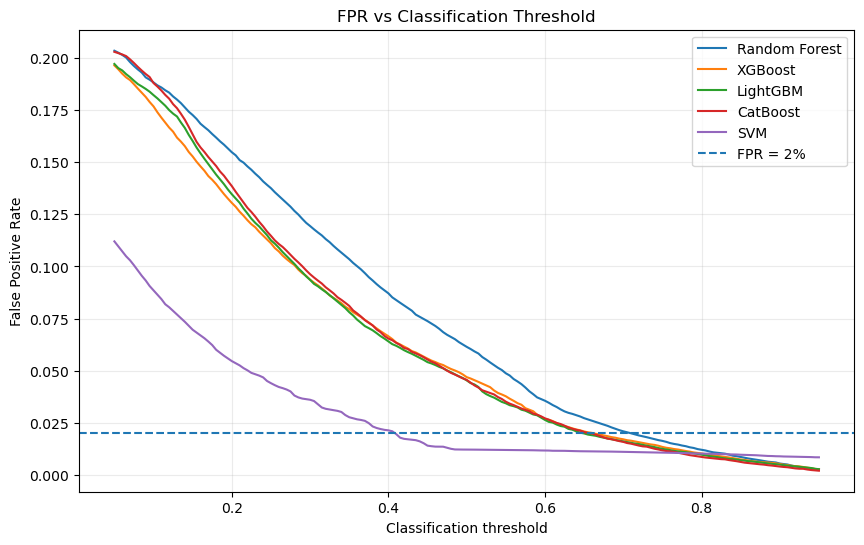

In [13]:
# 16. Inspect threshold curves

fig, ax = plt.subplots(figsize=(10, 6))

for name, result in threshold_results.items():
    ax.plot(result["Threshold"], result["FPR"], label=name)

ax.axhline(0.02, linestyle="--", label="FPR = 2%")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("False Positive Rate")
ax.set_title("FPR vs Classification Threshold")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

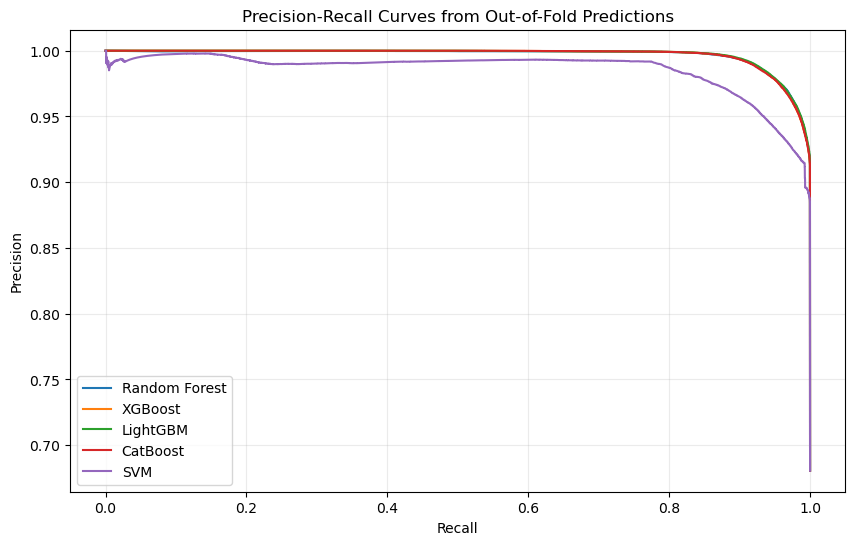

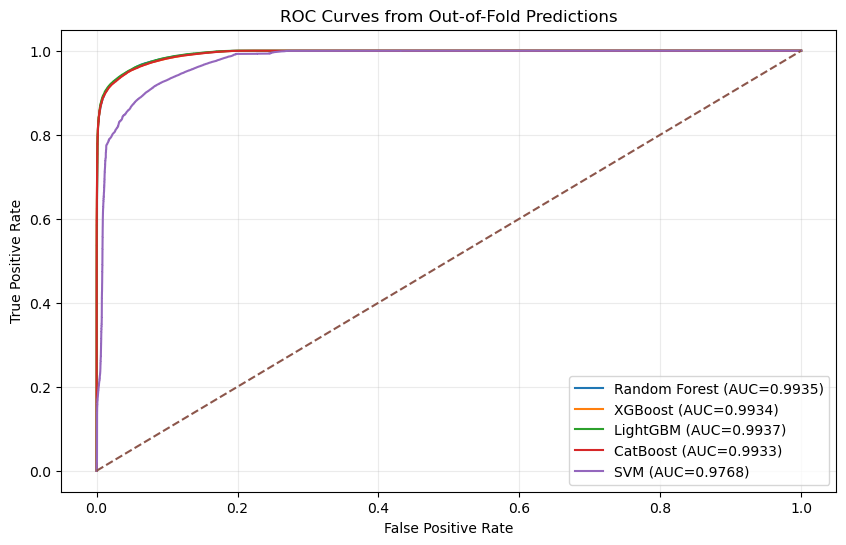

In [14]:
# 17. Precision-recall and ROC curves from OOF predictions

fig, ax = plt.subplots(figsize=(10, 6))

for name, scores in oof_scores.items():
    precision, recall, _ = precision_recall_curve(y_train, scores)
    ax.plot(recall, precision, label=name)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves from Out-of-Fold Predictions")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))

for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y_train, scores)
    auc = roc_auc_score(y_train, scores)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves from Out-of-Fold Predictions")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 18. Final CV comparison

In [15]:
# 18. Final training/CV comparison table

tuning_clean = tuning_summary.drop(columns=["Best_Params"]).copy()

final_comparison = threshold_summary.merge(
    tuning_clean, on="Model", how="left"
)

display(
    final_comparison[
        [
            "Model", "Threshold", "Accuracy", "Precision", "Recall",
            "F1", "ROC-AUC", "FPR", "FP", "FN",
            "Best_CV_F1", "Tuning_Time_min"
        ]
    ].sort_values("F1", ascending=False).round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,FP,FN,Best_CV_F1,Tuning_Time_min
2,LightGBM,0.650,0.9398,0.9899,0.9209,0.9542,0.9937,0.0199,1116.0,9443.0,0.9647,0.5990
0,Random Forest,0.715,0.9381,0.9902,0.9182,0.9528,0.9935,0.0195,1090.0,9763.0,0.9675,1.7341
1,XGBoost,0.665,0.9380,0.9900,0.9182,0.9527,0.9934,0.0197,1105.0,9767.0,0.9637,0.5635
3,CatBoost,0.660,0.9367,0.9899,0.9163,0.9517,0.9933,0.0199,1115.0,9984.0,0.9631,1.8080
4,SVM,0.410,0.8525,0.9885,0.7925,0.8797,0.9768,0.0196,1098.0,24763.0,0.9467,0.1988


In [16]:
# 19. Fold-level stability

stability = (
    cv_fold_table
    .groupby("Model")
    [["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "FPR"]]
    .agg(["mean", "std", "min", "max"])
)

display(stability.round(4))

Accuracy                         Precision                  \
                  mean     std     min     max      mean     std     min   
Model                                                                      
CatBoost        0.9516  0.0021  0.9490  0.9541    0.9780  0.0011  0.9766   
LightGBM        0.9528  0.0024  0.9508  0.9561    0.9781  0.0012  0.9767   
Random Forest   0.9570  0.0019  0.9548  0.9593    0.9710  0.0011  0.9698   
SVM             0.8154  0.0020  0.8136  0.8184    0.9923  0.0003  0.9919   
XGBoost         0.9519  0.0017  0.9503  0.9541    0.9774  0.0011  0.9760   

                       Recall          ...      F1         ROC-AUC          \
                  max    mean     std  ...     min     max    mean     std   
Model                                  ...                                   
CatBoost       0.9795  0.9502  0.0023  ...  0.9620  0.9658  0.9933  0.0004   
LightGBM       0.9799  0.9519  0.0025  ...  0.9634  0.9673  0.9937  0.0005   
Random Forest  0.9728  0.9657  0.0019  ...  0.9667  0.9700  0.9935  0.0004   
SVM            0.9928  0.7345  0.0031  ...  0.8423  0.8470  0.9768  0.0007   
XGBoost        0.9789  0.9513  0.0016  ...  0.9630  0.9659  0.9934  0.0004   

                                  FPR                          
                  min     max    mean     std     min     max  
Model                                                          
CatBoost       0.9930  0.9939  0.0456  0.0022  0.0426  0.0483  
LightGBM       0.9933  0.9943  0.0454  0.0025  0.0417  0.0482  
Random Forest  0.9931  0.9941  0.0614  0.0023  0.0576  0.0638  
SVM            0.9759  0.9779  0.0122  0.0005  0.0113  0.0128  
XGBoost        0.9929  0.9940  0.0469  0.0022  0.0438  0.0497  

[5 rows x 24 columns]

In [17]:
# 20. Default threshold (0.50) vs optimized threshold

threshold_comparison_rows = []

for name, scores in oof_scores.items():

    default_metrics = metrics_from_scores(y_train, scores, threshold=0.50)

    optimized_threshold = float(
        threshold_summary.loc[
            threshold_summary["Model"] == name,
            "Threshold"
        ].iloc[0]
    )

    optimized_metrics = metrics_from_scores(
        y_train, scores, threshold=optimized_threshold
    )

    threshold_comparison_rows.append({
        "Model": name,
        "Default_Threshold": 0.50,
        "Default_F1": default_metrics["F1"],
        "Default_Recall": default_metrics["Recall"],
        "Default_Precision": default_metrics["Precision"],
        "Default_FPR": default_metrics["FPR"],
        "Optimized_Threshold": optimized_threshold,
        "Optimized_F1": optimized_metrics["F1"],
        "Optimized_Recall": optimized_metrics["Recall"],
        "Optimized_Precision": optimized_metrics["Precision"],
        "Optimized_FPR": optimized_metrics["FPR"]
    })

threshold_comparison = pd.DataFrame(threshold_comparison_rows)
display(threshold_comparison.round(4))

,Model,Default_Threshold,Default_F1,Default_Recall,Default_Precision,Default_FPR,Optimized_Threshold,Optimized_F1,Optimized_Recall,Optimized_Precision,Optimized_FPR
0,Random Forest,0.5,0.9684,0.9657,0.9710,0.0614,0.715,0.9528,0.9182,0.9902,0.0195
1,XGBoost,0.5,0.9642,0.9513,0.9774,0.0469,0.665,0.9527,0.9182,0.9900,0.0197
2,LightGBM,0.5,0.9648,0.9519,0.9781,0.0454,0.650,0.9542,0.9209,0.9899,0.0199
3,CatBoost,0.5,0.9639,0.9502,0.9780,0.0456,0.660,0.9517,0.9163,0.9899,0.0199
4,SVM,0.5,0.8441,0.7345,0.9923,0.0122,0.410,0.8797,0.7925,0.9885,0.0196


# 21. Complementary-error analysis

The next stage asks whether the models make different mistakes. This is the evidence we need before building an ensemble.

**Important:** this analysis uses only the training-set OOF predictions. The official test set remains untouched and therefore remains a valid frozen external benchmark.

For each model we apply its OOF-optimized threshold, then measure:
- error-set similarity
- prediction disagreement
- how often one model recovers another model's mistakes
- complementary model pairs

In [18]:
# 22. Create OOF binary predictions at the optimized thresholds

model_names = list(oof_scores.keys())

oof_predictions = {}

for name in model_names:
    threshold = float(
        threshold_summary.loc[
            threshold_summary["Model"] == name,
            "Threshold"
        ].iloc[0]
    )

    oof_predictions[name] = (
        oof_scores[name] >= threshold
    ).astype(int)

print("Models in complementary-error analysis:")
print(model_names)

oof_prediction_df = pd.DataFrame(oof_predictions)
display(oof_prediction_df.head())

Models in complementary-error analysis:
['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'SVM']


,Random Forest,XGBoost,LightGBM,CatBoost,SVM
0,1,1,1,1,0
1,1,1,1,1,1
2,1,1,1,1,1
3,1,1,1,1,1
4,0,0,0,0,0


In [19]:
# 23. Pairwise error similarity

error_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

y_array = y_train.to_numpy()

for model_a in model_names:
    errors_a = oof_predictions[model_a] != y_array

    for model_b in model_names:
        errors_b = oof_predictions[model_b] != y_array

        intersection = np.sum(errors_a & errors_b)
        union = np.sum(errors_a | errors_b)

        error_matrix.loc[model_a, model_b] = (
            intersection / union if union > 0 else 0
        )

print("Pairwise Error Similarity (Jaccard)")
display(error_matrix.round(3))

Pairwise Error Similarity (Jaccard)


,Random Forest,XGBoost,LightGBM,CatBoost,SVM
Random Forest,1.000,0.759,0.764,0.745,0.302
XGBoost,0.759,1.000,0.802,0.784,0.308
LightGBM,0.764,0.802,1.000,0.806,0.300
CatBoost,0.745,0.784,0.806,1.000,0.323
SVM,0.302,0.308,0.300,0.323,1.000


In [20]:
# 24. Pairwise prediction disagreement

disagreement_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

for model_a in model_names:
    for model_b in model_names:
        disagreement_matrix.loc[model_a, model_b] = np.mean(
            oof_predictions[model_a] != oof_predictions[model_b]
        )

print("Pairwise Prediction Disagreement (%)")
display((disagreement_matrix * 100).round(2))

Pairwise Prediction Disagreement (%)


,Random Forest,XGBoost,LightGBM,CatBoost,SVM
Random Forest,0.00,1.70,1.64,1.83,11.22
XGBoost,1.70,0.00,1.34,1.52,11.09
LightGBM,1.64,1.34,0.00,1.33,11.19
CatBoost,1.83,1.52,1.33,0.00,10.78
SVM,11.22,11.09,11.19,10.78,0.00


In [21]:
# 25. Error recovery: when model B gets model A's errors right

recovery_rows = []

for model_a in model_names:
    pred_a = oof_predictions[model_a]
    errors_a = pred_a != y_array

    for model_b in model_names:
        if model_a == model_b:
            continue

        pred_b = oof_predictions[model_b]
        recovered = errors_a & (pred_b == y_array)

        total_errors = int(errors_a.sum())
        recovered_count = int(recovered.sum())

        recovery_rows.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "A_Errors": total_errors,
            "B_Recovers_A_Errors": recovered_count,
            "Recovery_Rate": (
                recovered_count / total_errors
                if total_errors > 0 else 0
            )
        })

recovery_df = pd.DataFrame(recovery_rows)

display(
    recovery_df
    .sort_values("Recovery_Rate", ascending=False)
    .round(4)
)

,Model_A,Model_B,A_Errors,B_Recovers_A_Errors,Recovery_Rate
18,SVM,LightGBM,25861,17458,0.6751
16,SVM,Random Forest,25861,17337,0.6704
17,SVM,XGBoost,25861,17214,0.6656
19,SVM,CatBoost,25861,16828,0.6507
3,Random Forest,SVM,10853,2329,0.2146
7,XGBoost,SVM,10872,2225,0.2047
11,LightGBM,SVM,10559,2156,0.2042
15,CatBoost,SVM,11099,2066,0.1861
12,CatBoost,Random Forest,11099,1730,0.1559
1,Random Forest,LightGBM,10853,1581,0.1457


In [22]:
# 26. Complementary model pairs

pair_rows = []

for i, model_a in enumerate(model_names):
    for model_b in model_names[i + 1:]:

        errors_a = oof_predictions[model_a] != y_array
        errors_b = oof_predictions[model_b] != y_array

        intersection = np.sum(errors_a & errors_b)
        union = np.sum(errors_a | errors_b)

        error_similarity = (
            intersection / union if union > 0 else 0
        )

        disagreement = np.mean(
            oof_predictions[model_a] != oof_predictions[model_b]
        )

        pair_rows.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "Error_Similarity": error_similarity,
            "Prediction_Disagreement": disagreement
        })

pairwise_complementarity = pd.DataFrame(pair_rows)

print("Most complementary pairs appear toward lower error similarity / higher disagreement.")
display(
    pairwise_complementarity
    .sort_values("Error_Similarity")
    .round(4)
)

Most complementary pairs appear toward lower error similarity / higher disagreement.


,Model_A,Model_B,Error_Similarity,Prediction_Disagreement
8,LightGBM,SVM,0.2999,0.1119
3,Random Forest,SVM,0.3024,0.1122
6,XGBoost,SVM,0.3079,0.1109
9,CatBoost,SVM,0.3235,0.1078
2,Random Forest,CatBoost,0.7446,0.0183
0,Random Forest,XGBoost,0.7591,0.0170
1,Random Forest,LightGBM,0.7638,0.0164
5,XGBoost,CatBoost,0.7839,0.0152
4,XGBoost,LightGBM,0.8020,0.0134
7,LightGBM,CatBoost,0.8062,0.0133


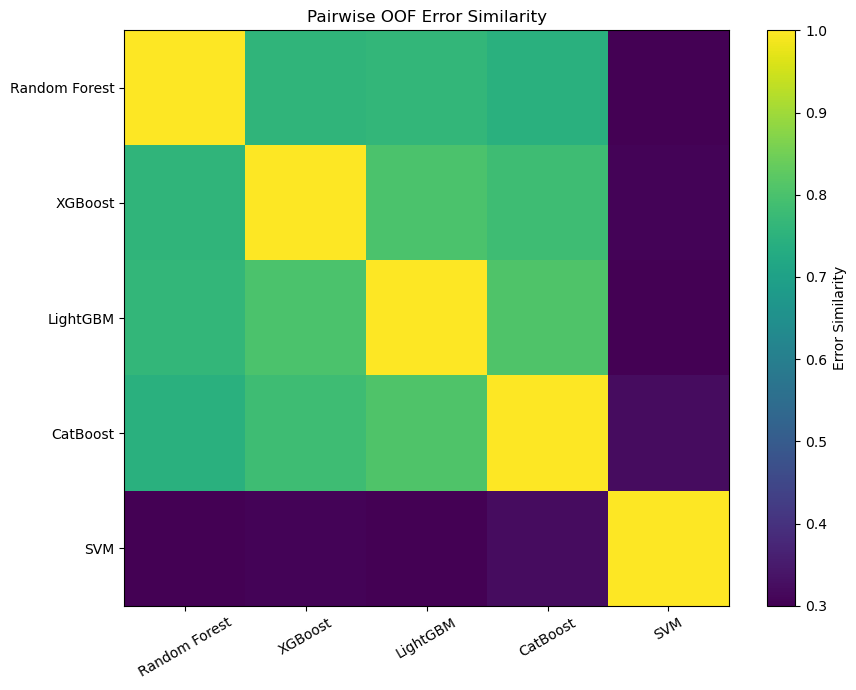

In [23]:
# 27. Error similarity heatmap

plt.figure(figsize=(9, 7))
plt.imshow(error_matrix.values, aspect="auto")
plt.colorbar(label="Error Similarity")
plt.xticks(range(len(model_names)), model_names, rotation=30)
plt.yticks(range(len(model_names)), model_names)
plt.title("Pairwise OOF Error Similarity")
plt.tight_layout()
plt.show()

In [24]:
# 28. Complementarity summary

best_error_pair = pairwise_complementarity.sort_values(
    "Error_Similarity"
).iloc[0]

best_disagreement_pair = pairwise_complementarity.sort_values(
    "Prediction_Disagreement", ascending=False
).iloc[0]

print("=" * 70)
print("COMPLEMENTARY ERROR ANALYSIS SUMMARY")
print("=" * 70)

print("\nLowest error similarity:")
print(
    f"{best_error_pair['Model_A']} + {best_error_pair['Model_B']}"
)
print(
    f"Error similarity: {best_error_pair['Error_Similarity']:.4f}"
)

print("\nHighest prediction disagreement:")
print(
    f"{best_disagreement_pair['Model_A']} + "
    f"{best_disagreement_pair['Model_B']}"
)
print(
    f"Disagreement: {best_disagreement_pair['Prediction_Disagreement']:.4f}"
)

print("\nOOF optimized-threshold performance:")
display(
    threshold_summary[
        ["Model", "Threshold", "F1", "Precision", "Recall", "FPR"]
    ]
    .sort_values("F1", ascending=False)
    .round(4)
)

COMPLEMENTARY ERROR ANALYSIS SUMMARY

Lowest error similarity:
LightGBM + SVM
Error similarity: 0.2999

Highest prediction disagreement:
Random Forest + SVM
Disagreement: 0.1122

OOF optimized-threshold performance:


,Model,Threshold,F1,Precision,Recall,FPR
2,LightGBM,0.650,0.9542,0.9899,0.9209,0.0199
0,Random Forest,0.715,0.9528,0.9902,0.9182,0.0195
1,XGBoost,0.665,0.9527,0.9900,0.9182,0.0197
3,CatBoost,0.660,0.9517,0.9899,0.9163,0.0199
4,SVM,0.410,0.8797,0.9885,0.7925,0.0196


# 29. Ready for the ensemble stage

At this point the binary individual-model stage is complete. The notebook has produced:

- tuned models for five candidates
- fresh 5-fold OOF predictions
- default-threshold metrics
- optimized operating thresholds
- PR and ROC curves
- fold-level stability
- complementary-error analysis
- candidate pairs for ensemble construction

### Next stage
Use the **OOF scores** to build and validate the ensemble. Ensemble architecture and threshold selection should be decided from training/validation data, and the previously obtained official test results should remain untouched until the final frozen ensemble is ready.

**No fitted model is saved anywhere in this notebook.**

In [25]:
# ============================================================
# SAVE TRAINED MODELS
# ============================================================

import os
import joblib

MODEL_DIR = "saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

for name, model in tuned_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".joblib"
    )

    path = os.path.join(MODEL_DIR, filename)

    joblib.dump(model, path)

    print(f"Saved: {path}")

print("\nAll models saved successfully.")

Saved: saved_models\random_forest.joblib
Saved: saved_models\xgboost.joblib
Saved: saved_models\lightgbm.joblib
Saved: saved_models\catboost.joblib
Saved: saved_models\svm.joblib

All models saved successfully.


In [26]:
# ============================================================
# SAVE OPTIMIZED THRESHOLDS
# ============================================================

thresholds = {
    "Random Forest": 0.715,
    "XGBoost": 0.665,
    "LightGBM": 0.650,
    "CatBoost": 0.660,
    "SVM": 0.410
}

joblib.dump(
    thresholds,
    os.path.join(MODEL_DIR, "thresholds.joblib")
)

print("Saved: saved_models/thresholds.joblib")

Saved: saved_models/thresholds.joblib


In [27]:
# ============================================================
# SAVE FEATURE LIST
# ============================================================

selected_features = [
    'ct_dst_src_ltm',
    'sttl',
    'sbytes',
    'smean',
    'dmean',
    'dttl',
    'dbytes',
    'ct_state_ttl',
    'service_none',
    'ct_dst_sport_ltm',
    'dload',
    'proto_udp',
    'sloss',
    'state_int',
    'proto_tcp',
    'service_http',
    'tcprtt',
    'swin',
    'response_body_len'
]

joblib.dump(
    selected_features,
    os.path.join(MODEL_DIR, "selected_features.joblib")
)

print("Saved: saved_models/selected_features.joblib")

Saved: saved_models/selected_features.joblib


In [28]:
# ============================================================
# VERIFY SAVED ARTIFACTS
# ============================================================

print("\nSaved files:")
for file in sorted(os.listdir(MODEL_DIR)):
    print(" -", file)


Saved files:
 - catboost.joblib
 - lightgbm.joblib
 - random_forest.joblib
 - selected_features.joblib
 - selected_features_20.pkl
 - svm.joblib
 - thresholds.joblib
 - tuned_catboost.pkl
 - tuned_lightgbm.pkl
 - tuned_mlp.pkl
 - tuned_random_forest.pkl
 - tuned_xgboost.pkl
 - xgboost.joblib
